# Image Manipulation and Edge Detection

---

Prof. Dr.-Ing. Antje Muntzinger, Hochschule für Technik Stuttgart

antje.muntzinger@hft-stuttgart.de

---

In this notebook, we practice some basic image manipulation techniques in OpenCV including Canny edge detection. These are the foundation of later computer vision applications.

**NOTE:** You may answer in English or German.

In [1]:
# imports
from matplotlib import pyplot as plt
%matplotlib inline

import numpy as np 
import cv2

Task 1: Basic Image Manipulation in OpenCV
=

**TODO**: 1a) Load the image 'HFT_Bau1.jpg'. Convert it to a color format of your choice, and display it. **(1.5 points)**

<function matplotlib.pyplot.show(close=None, block=None)>

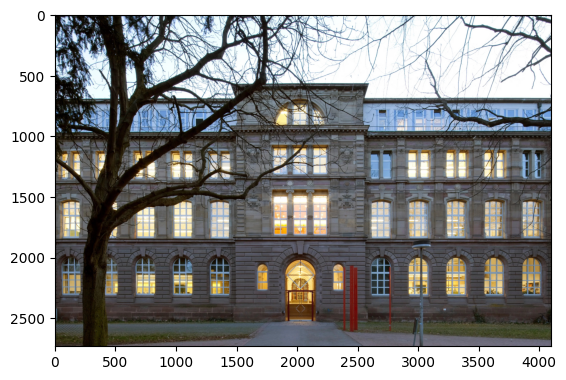

In [2]:
##### TODO: YOUR CODE GOES HERE

input_img = cv2.imread ('images/HFT_Bau1.jpg') 

img_RGB = cv2.cvtColor(input_img, cv2.COLOR_BGR2RGB)

plt.imshow(img_RGB)
plt.show

**TODO**: 1b) Color the 10th pixel row of the image in red. Plot the upper left 500x500 pixel image cutout to verify your result. **(2 points)** 

Hint: Indexing starts at 0 in Python! Remember the image origin is in the upper left image corner.

In [ ]:
##### TODO: YOUR CODE GOES HERE


**TODO**: 1c) Print the color values of the rightmost Pixel in the 9th row, as well as the color values of the leftmost Pixel in the 10th row. **(2 points)** 

In [ ]:
##### TODO: YOUR CODE GOES HERE


**TODO**: 1d) Flatten the color image, i.e., convert it from the 3D array to a 1D array. Find at least two different commands that achieve the desired result. Check your output with `shape`. **(3 points)**

In [ ]:
##### TODO: YOUR CODE GOES HERE


**TODO**: 1e) As before, print the color values of the rightmost Pixel in the 9th row, as well as the color values of the leftmost Pixel in the 10th row, but use the flattened image now. Verify that the result is the same as before. **(2 points)**

In [ ]:
##### TODO: YOUR CODE GOES HERE


**TODO**: 1f) Split the three color channels and display them separately. Can you see from the plotted images which color channel is displayed in which image (without looking at the code), or do the three channels not differ much? Write your answer in the markdown cell below the code. **(2 points)**

In [ ]:
##### TODO: YOUR CODE GOES HERE


**YOUR ANSWER**: 

Task 2: Edge Detection
=

**TODO**: 2a) Choose a part of the image that you find interesting for later corner and edge detection. Store the cutout in a new grayscale image. **(1 point)**

<function matplotlib.pyplot.show(close=None, block=None)>

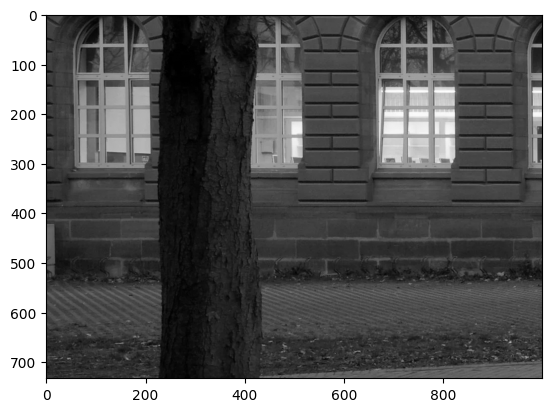

In [ ]:
##### TODO: YOUR CODE GOES HERE

cutout_gray = cv2.cvtColor(img_RGB[2000:, 0:1000], cv2.COLOR_RGB2GRAY)

plt.imshow(cutout_gray, cmap='grey')
plt.show


**TODO**: 2b) Find a part of the cutout that you think might be difficult to detect edges in with Canny. Mark this part in the grayscale cutout with a red rectangle. Write a short explanation why this could be difficult below. **(2 points)**

Hint: Note that you cannot plot color into a grayscale image. One option is to convert the grayscale image to RGB first, using `COLOR_GRAY2RGB`.

"\nThe edge between the tree and the building will be difficult to detect because the pixel intensities surrounding the edge are very similar, resulting in a low gradient that therefore probably won't surpass the threshold.\n"

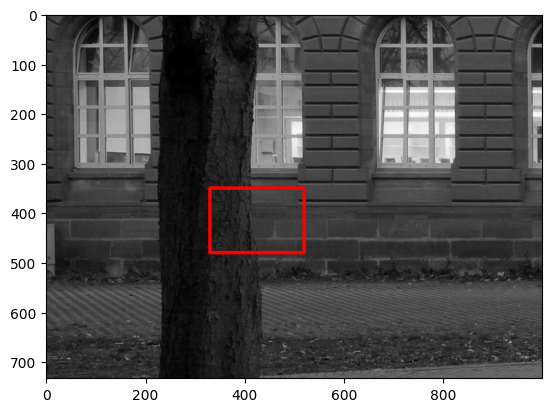

In [191]:
##### TODO: YOUR CODE GOES HERE

img_marked = cv2.cvtColor(cutout_gray.copy(), cv2.COLOR_GRAY2RGB)

cv2.rectangle(img_marked, (330, 350), (520,480), color=(255, 0, 0), thickness=5)

plt.imshow(img_marked)
plt.show

'''
The edge between the tree and the building will be difficult to detect because the pixel intensities surrounding the edge are very similar, resulting in a low gradient that therefore probably won't surpass the threshold.
'''

**YOUR ANSWER**: 

The edge between the tree and the building will be difficult to detect because the pixel intensities surrounding the edge are very similar, resulting in a low gradient that therefore probably won't surpass the threshold.

**TODO**: 2c) Resize the gray cutout to 1/4th of the original size, keeping the aspect ratio. Plot both grayscale images next to each other using Matplotlib's `subplots`. **(2 points)**

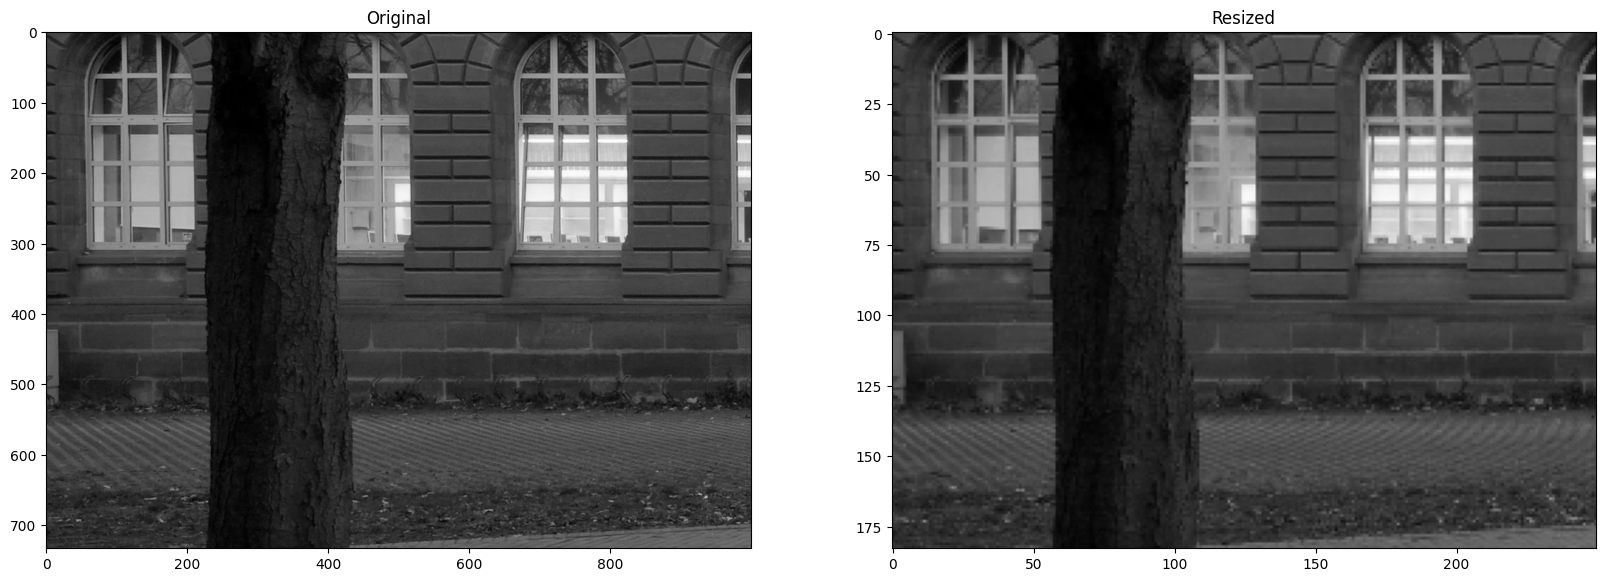

In [35]:
##### TODO: YOUR CODE GOES HERE

resized = cv2.resize(cutout_gray, None, fx=0.25, fy=0.25)

fig, (ax1, ax2) = plt.subplots(1,2, figsize=(20, 15))
ax1.imshow(cutout_gray, cmap='gray')
ax1.title.set_text('Original')
ax2.imshow(resized, cmap='gray')
ax2.title.set_text('Resized')


**TODO**: 2d) Apply Gaussian blur with a kernel of size 9 to the resized image and plot the result. **(1 point)**

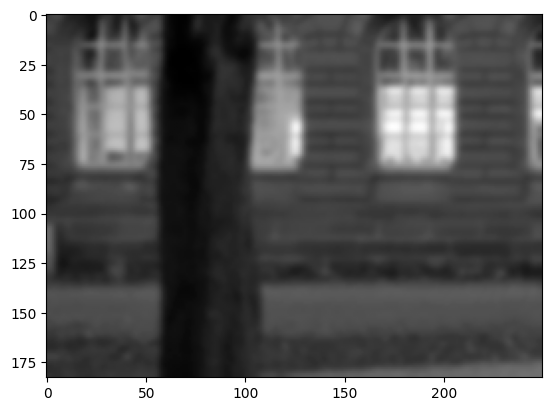

In [183]:
##### TODO: YOUR CODE GOES HERE
d=4
blurred_Gaussian = cv2.GaussianBlur(resized, ksize=(d*2+1, d*2+1), sigmaX=0, sigmaY=0) 

plt.imshow(blurred_Gaussian, cmap='grey')
plt.show()


**TODO**: 2e) Detect the edges in the blurred cutout using Canny edge detector. Adapt the Canny thresholds for an optimal result. Plot the edges in blue into the grayscale cutout. **(3 points)** 

"\na) Yes, my prediction about the tree infront of the building was right. the intensity on the lighter side is to similar to the builing. Also the structure on the Bricks are hard to catch.\n\nb) Also yes, The shadow on the tree creates an edge that in reality is not there. We have the same problem with the leafes on the ground.\n\nI tried solving the tree-edge issue by lowering the lower threshold so the edge would continue thoughout the whole edge of the tree. This didn't result in the wanted output as more and more edges got detect in the leafes on the ground and in the shadow on the tree. I also tried lowering the kernel size to detect the brick structure better as there is not much noise and the gaps are close togehter, this also didn't help as more and more unwanted edges got detected. It always came down to a trade of between false positives and false negatives.\n"

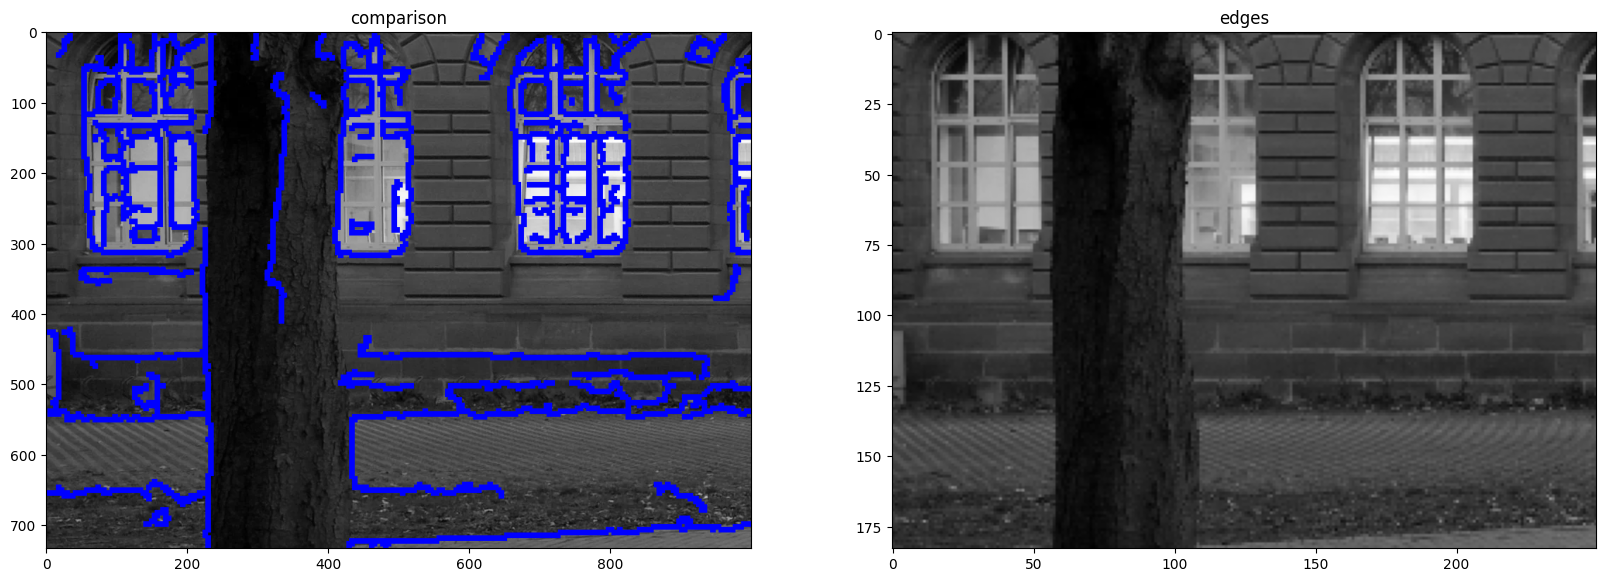

In [ ]:
##### TODO: YOUR CODE GOES HERE

threshold1 = 20
threshold2 = 60  

edges = cv2.Canny(blurred_Gaussian, threshold1, threshold2)
edges = cv2.resize(edges, dsize=(cutout_gray.shape[1], cutout_gray.shape[0]))


cutout_w_edge = cv2.cvtColor(cutout_gray, cv2.COLOR_GRAY2RGB)

cutout_w_edge[edges != 0] = (0, 0, 255)

fig, (ax1, ax2) = plt.subplots(1,2, figsize=(20, 15))
ax1.imshow(cutout_w_edge)
ax1.title.set_text('comparison')
ax2.imshow(resized, cmap='gray')
ax2.title.set_text('edges')

'''
a) Yes, my prediction about the tree infront of the building was right. the intensity on the lighter side is to similar to the builing. Also the structure on the Bricks are hard to catch.

b) Also yes, The shadow on the tree creates an edge that in reality is not there. We have the same problem with the leafes on the ground.

I tried solving the tree-edge issue by lowering the lower threshold so the edge would continue thoughout the whole edge of the tree. This didn't result in the wanted output as more and more edges got detect in the leafes on the ground and in the shadow on the tree. I also tried lowering the kernel size to detect the brick structure better as there is not much noise and the gaps are close togehter, this also didn't help as more and more unwanted edges got detected. It always came down to a trade of between false positives and false negatives.
'''

**TODO**: 2f) Check if your prediction of difficulty was correct. Do you see a) real edges that were missed by Canny (false negatives) or b) detected edges that are not there in reality (false positives)? Try to experiment with the Canny thresholds and solve these difficulties. How did you try to solve the difficulties? Write your answer below the code. **(1.5 points)**

**YOUR ANSWER**: 

a) Yes, my prediction about the tree infront of the building was right. the intensity on the lighter side is to similar to the builing. Also the structure on the Bricks are hard to catch.

b) Also yes, The shadow on the tree creates an edge that in reality is not there. We have the same problem with the leafes on the ground.

I tried solving the tree-edge issue by lowering the lower threshold so the edge would continue thoughout the whole edge of the tree. This didn't result in the wanted output as more and more edges got detect in the leafes on the ground and in the shadow on the tree. I also tried lowering the kernel size to detect the brick structure better as there is not much noise and the gaps are close togehter, this also didn't help as more and more unwanted edges got detected. It always came down to a trade of between false positives and false negatives.

Well done, you are now able to apply basic image manipulation techniques as well as Canny edge detection to images in OpenCV! 

Task 3: Theory Questions
=

**TODO**: 3a) What is the problem of applying image derivatives for edge detection in noisy images? What is a possible solution to that problem? Can you give an example in which you often get noise when taking a photo? **(3 points)**

**YOUR ANSWER**: 

**TODO**: 3b) You are given a 3×3 pixel input image $
\begin{array}{|ccc|}
\hline
 1 & 2 & 1  \\ 
 2 & 2 & 2  \\ 
 3 & 2 & 3  \\ 
\hline   
\end{array}$
and a 3×3 pixel filter $\begin{array}{|ccc|}
\hline
 -1 & 0 & 1  \\ 
 -1 & 0 & 1  \\ 
 -1 & 0 & 1  \\ 
\hline   
\end{array}$. Compute the 3 × 3 pixel result image of the correlation of the filter with the input image. All pixels outside the input image are padded with zeros. **(4.5 points)**

**YOUR ANSWER**: 


**TODO**: 3c) What patterns does this special filter respond to? How can you see this in the result from 3b)? **(2 points)**

**YOUR ANSWER**: 

**TODO**: 3d) Please calculate the result using the settings from task 3b), but with convolution instead of correlation. **(4.5 points)**

**YOUR ANSWER**: 
